# Taller 6 — Mini proyecto MCP con LLM y LangChain

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yeavil-neny/NLP-ProcesamientoLeguajeNatural/blob/main/Taller_6/proyecto_mcp_chatbot_recetas.ipynb)

## Caso propio: asistente culinario conversacional con servidores MCP propios (documentos de recetas + utilidades de cocina)

## 1. El problema y el papel del Model Context Protocol (MCP)

El RAG del taller anterior resolvió el conocimiento estático del LLM con una memoria externa citable. Pero quedaba una segunda limitación: **todo el conocimiento tenía que pasar por el vector store**, y el modelo seguía sin poder *actuar*: no podía calcular, convertir unidades ni escalar cantidades sin que se le re-entrenara o se le escribiera lógica ad hoc.

**Model Context Protocol (MCP)** ([specificación, 2026-07-28](https://modelcontextprotocol.io/specification/2026-07-28)) es el estándar abierto que resuelve esto: un protocolo entre aplicaciones que exponen capacidades (**host**) y los LLM que las consumen, con tres roles bien definidos:

- **Host**: la aplicación con el LLM (aquí, el notebook con el agente de LangChain).
- **Cliente**: el conector que mantiene una sesión `1:1` con un servidor (aquí, `MultiServerMCPClient`, de `langchain-mcp-adapters`).
- **Servidores MCP**: programas pequeños que exponen **herramientas** (tools) con su esquema de entrada, su descripción y su resultado.

La arquitectura del caso propio es:

```text
                        Usuario (Gradio)
                              |
                 Agente LangChain (host) + llama3.2:3b
                              |
              cliente MCP: MultiServerMCPClient
                 |                       |
        HTTP :9090 (streamable-http)   HTTP :9091 (streamable-http)
                 |                       |
    ┌──────────────────────────┐   ┌──────────────────────────┐
    │  Servidor RecetasDocMCP  │   │ Servidor CocinaUtilsMCP   │
    │  buscar_recetas(consulta)│   │ convertir_volumen(frase)  │
    │  leer_receta(id)         │   │ escalar_cantidad(frase,f) │
    │  corpus RecetasDeLaAbuela│   │ calcular_kcal(gramos,al.) │
    │  -> RESPUESTAS CON URL   │   │ -> resultado exacto      │
    └──────────────────────────┘   └──────────────────────────┘
```

### 1.1 ¿Por qué este caso y por qué dos servidores separados?

1. **Documentos con cita obligatoria**: el servidor de recetas devuelve, en cada hit, la URL de la página web de origen; el chatbot puede responder "con referencias a los documentos usados", exactamente lo que se pide en la demo de la entrega (video).
2. **Cómputo exacto, no alucinado**: el LLM es pésimo multiplicando gramos o convirtiendo tazas; una tool MCP determinística lo hace perfecto (igual que el rol de la `calculadora` en los ejemplos guía, aunque aquí con dominio y datos propios).
3. **Separación de responsabilidades**: documentos y cálculo no comparten estado, y separarlos en dos servidores independiente demuestra la propiedad clave de MCP: **un host consume N servidores heterogéneos por el mismo protocolo**, sin cambiar nada del agente.

## 2. Configuración del entorno

In [31]:
import warnings

warnings.filterwarnings('ignore')

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print('¿Ejecutando en Google Colab?', IN_COLAB)


¿Ejecutando en Google Colab? True


Se instalan las librerías con las mismas versiones acotadas que en los notebooks guía de la sesión (`mcp>=1.24`, `langchain-mcp-adapters>=0.3`), más las del corpus y el EDA (`datasets`, `pandas`, `matplotlib`, `wordcloud`).

In [32]:
!test '{IN_COLAB}' = 'True' && pip install -q "mcp>=1.24.0,<2.0.0" "langchain-mcp-adapters>=0.3.0,<0.4.0" langchain langchain-core langchain-ollama langgraph httpx gradio ollama datasets pandas matplotlib wordcloud

# En local, instalar con su gestor de paquetes de preferencia.


### 2.1 Servidores MCP propios: obtención de los archivos

Los dos servidores MCP del caso propio están en `Taller_6/mcp_servers/` del repositorio del equipo. En Colab, al abrir el notebook desde GitHub, los archivos auxiliares no siempre se descargan, así que hay una celda de *bootstrap* que los trae, igual que en los notebooks guía. En local bastan los archivos del repositorio.

In [33]:
# En Colab se descargan los servidores propios desde el repositorio del equipo,
# porque al abrir un notebook desde GitHub los archivos auxiliares no se bajan.
is_colab = bool(globals().get('IN_COLAB', False))
if is_colab:
    !mkdir -p mcp_servers
    !wget -q -O mcp_servers/recetas_mcp_server.py https://github.com/yeavil-neny/NLP-ProcesamientoLeguajeNatural/raw/refs/heads/main/Taller_6/mcp_servers/recetas_mcp_server.py
    !wget -q -O mcp_servers/cocina_mcp_server.py https://github.com/yeavil-neny/NLP-ProcesamientoLeguajeNatural/raw/refs/heads/main/Taller_6/mcp_servers/cocina_mcp_server.py
    print('Servidores MCP del caso propio descargados para Colab.')
else:
    print('Entorno local detectado: se usan los archivos del repositorio.')


Servidores MCP del caso propio descargados para Colab.


## 3. El corpus: `RecetasDeLaAbuela` (mismo dominio del taller anterior, ahora como documentos MCP)

Se reutiliza el corpus culinario hispanoamericano `somosnlp/RecetasDeLaAbuela` (versión curada `version_1`, 20.236 recetas raspadas de webs de cocina con título, URL original, ingredientes, pasos y metadatos). La decisión es deliberada: en el Taller 5 estas recetas se *incrustaron* en un índice vectorial y el agente era un RAG monolítico; aquí el mismo contenido se servirá por **dos servidores MCP con herramientas declaradas**, lo que permite comparar las dos filosofías sobre datos idénticos.

In [34]:
# Carga del dataset de Hugging Face y renombrado de columnas a snake_case,
# igual que en el Taller 5, para que la curación sea idéntica entre talleres.
import pandas as pd

pd.set_option('display.max_colwidth', 60)

from datasets import get_dataset_config_names, load_dataset

configs = get_dataset_config_names('somosnlp/RecetasDeLaAbuela')
print('Configuraciones:', configs)

dataset = load_dataset('somosnlp/RecetasDeLaAbuela', 'version_1', split='train')

dataset = dataset.rename_columns({
    'Id': 'id', 'Nombre': 'nombre', 'URL': 'url', 'Ingredientes': 'ingredientes',
    'Pasos': 'pasos', 'Pais': 'pais', 'Duracion': 'duracion', 'Categoria': 'categoria',
    'Comensales': 'comensales', 'Dificultad': 'dificultad',
})
KEEP = ['id', 'nombre', 'url', 'ingredientes', 'pasos', 'pais', 'duracion', 'categoria', 'comensales', 'dificultad']
dataset = dataset.remove_columns([c for c in dataset.column_names if c not in KEEP])
dataset.set_format(type='pandas')
df_raw = dataset.to_pandas()
df_raw.head(10)


Configuraciones: ['version_inicial', 'version_1']


,id,nombre,url,ingredientes,pasos,pais,duracion,categoria,comensales,dificultad
0,1,Tacos Dorados de Papa,https://www.mexicoenmicocina.com/tacos-dorados-de-papa/,"½ taza de cilantro finamente picado, 1 taza de tomate pi...",Pon las papas enteras en una olla mediana y cúbrelas con...,MEX,01:00,vegetarianos,6,None
1,2,Ensalada de Chayotes,https://www.mexicoenmicocina.com/receta-ensalada-de-chay...,"½ cucharadita sal, ¼ cucharadita de pimienta recién moli...",Coloca los chayotes en una cacerola y cúbralos con agua;...,MEX,00:25,vegetarianos,4,None
2,3,Huevos a la Mexicana,https://www.mexicoenmicocina.com/huevos-a-la-mexicana/,"½ Chile Serrano cortado en pequeños trocitos*, 2 huevos ...",Calienta el aceite en una sartén mediana a fuego medio-a...,MEX,00:15,vegetarianos,1,None
3,4,Rajas de Chile Poblano con Crema,https://www.mexicoenmicocina.com/rajas-de-chile-poblano-...,"½ cucharadita Sal, 2 cucharadas de aceite vegetal, 1 ceb...",Para asar los chiles:Colocas los chiles ya limpios direc...,MEX,00:30,vegetarianos,None,None
4,5,Papas a la Mexicana,https://www.mexicoenmicocina.com/papas-a-la-mexicana/,"⅓ taza de cebolla blanca en cubitos, Sal al gusto., 6 To...",Calienta el aceite vegetal en una sartén grande a fuego ...,MEX,00:25,vegetarianos,None,None
5,6,Nopalitos navegantes,https://www.mexicoenmicocina.com/nopalitos-navegantes/,"4 huevos, Sal y pimienta al gusto., 3 Nopales grandes co...",Llena una cacerola de tamaño mediano con agua y colócala...,MEX,00:30,vegetarianos,4,None
6,7,Guacamole Casero,https://www.mexicoenmicocina.com/guacamole-casero/,"1 chile serrano, 4-5 Ramitas de Cilantro, Sal al gusto, ...",Corta la cebolla y el Chile Serrano (si no quieres que s...,MEX,00:20,vegetarianos,1,None
7,8,Calabacitas al vapor,https://www.mexicoenmicocina.com/calabacitas-al-vapor/,2 calabazas de tamaño mediano o calabacín cortada en rod...,Coloca la calabaza en rodajas en una sartén de tamaño me...,MEX,00:15,vegetarianos,4,None
8,9,Sopa de Calabacitas con Elote,https://www.mexicoenmicocina.com/sopa-de-calabacitas-con...,"1 Diente de ajo pequeño picado, 1 Caldo de Pollo Knorr -...",Sirva en cuencos y decorar con queso fresco desmenuzado ...,MEX,00:30,vegetarianos,2,None
9,10,Pasta con salsa cremosa de chile poblano,https://www.mexicoenmicocina.com/pasta-con-salsa-cremosa/,"1 diente de ajo grande o 2 pequeños, ½ taza de leche, 2 ...","Mientras preparamos la salsa, cocina la pasta de acuerdo...",MEX,00:30,vegetarianos,4,None


### 3.1 EDA compacto del corpus

El EDA completo (nulos, longitudes, léxico, nube de palabras) está en el Taller 5 sobre el mismo dataset; aquí se repiten solo las dos vistas que justifican las decisiones de diseño del servidor MCP: la completitud de los campos citables y la distribución por país.

In [35]:
# Completitud de los campos que el servidor MCP usará para citar y filtrar.
nulls = df_raw.isnull().sum()
print('Recetas crudas:', len(df_raw))
print('\nNulos por columna:')
for col, n in nulls.items():
    print(f'  {col:<12} {n:>6} ({n / len(df_raw):.1%})')


Recetas crudas: 20236

Nulos por columna:
  id                0 (0.0%)
  nombre            0 (0.0%)
  url               0 (0.0%)
  ingredientes      0 (0.0%)
  pasos             0 (0.0%)
  pais           5591 (27.6%)
  duracion       6630 (32.8%)
  categoria      6748 (33.3%)
  comensales     6627 (32.7%)
  dificultad     6454 (31.9%)


**Observación (corrida real).** Los campos con los que el servidor construye las citas (`id`, `nombre`, `url`) y el contenido técnico (`ingredientes`, `pasos`) llegaron al 100% en las 20.236 recetas crudas, mientras que los metadatos descriptivos concentran los nulos alrededor del 30% (`pais` 27.6%, `duracion` 32.8%, `categoria` 33.3%, `comensales` 32.7%, `dificultad` 31.9%). Consecuencia: la curación puede exigir URL sin perder contenido útil, porque sin fuente no hay cita verificable para el video, y el chatbot no puede prometer atributos (país, duración) que en un tercio del corpus no existen.

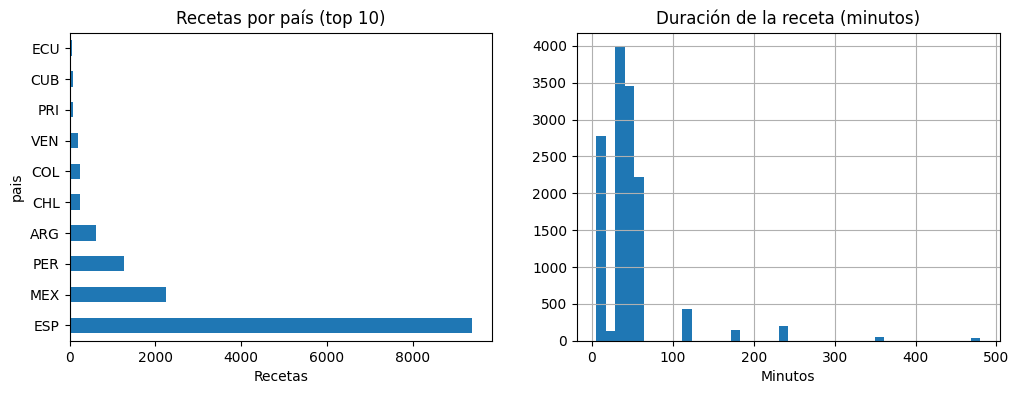

In [36]:
# Distribución por país: define qué recetas priorizará el buscador por defecto.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(df_raw.pais.value_counts().head(10)).plot.barh(ax=ax[0])
ax[0].set_title('Recetas por país (top 10)')
ax[0].set_xlabel('Recetas')

minutos = df_raw.duracion.dropna().str.split(':').apply(
    lambda p: int(p[0]) * 60 + int(p[1]) if len(p) == 2 else None).dropna()
minutos.hist(ax=ax[1], bins=40)
ax[1].set_title('Duración de la receta (minutos)')
ax[1].set_xlabel('Minutos')
plt.show()


**Observación (corrida real).** El desbalance por país quedó confirmado y es fuerte: España domina con algo más de 9.000 recetas (cerca de la mitad del corpus), seguida de México (~2.100) y Perú (~1.100); los demás países quedan por debajo de los 500 registros y Colombia no llega a los 250. En duraciones, casi todo el corpus declara tiempos inferiores a una hora, con la mayor concentración entre los 10 y los 20 minutos y una cola aislada que llega a unos 490 minutos. Consecuencia práctica: las citas del chatbot provendrán sobre todo de webs gastronómicas de España y México.

### 3.2 Curación y preparación del corpus para el servidor MCP

La misma curación mínima y determinística del Taller 5 (registros vacíos, URLs no válidas, duplicados por URL, longitud mínima de 25 palabras en los pasos), más un paso nuevo: **serializar el corpus curado a JSON** para que el servidor MCP lo consuma. El servidor no conoce Hugging Face ni `pandas`: su única dependencia de datos es el archivo `recetas_corpus.json`.

In [37]:
# Curación idéntica a la del Taller 5, para que ambos talleres sirvan el
# mismo corpus. Filtros: registros vacios, URL no valida, duplicados por URL
# y recetas con menos de 25 palabras de procedimiento.
def curar(df):
    vacios = df.nombre.isna() | df.url.isna() | df.pasos.isna()
    df = df[~vacios].copy()
    df = df[df.url.str.startswith('http')]
    df = df.drop_duplicates(subset='url')
    n_pasos = df.pasos.apply(lambda t: len(t.split()))
    df = df[n_pasos >= 25]
    return df.reset_index(drop=True)

df = curar(df_raw)
print(f'Recetas después de la curación: {len(df)} '
      f'(de {len(df_raw)} crudas, {len(df_raw) - len(df)} eliminadas)')


Recetas después de la curación: 19249 (de 20236 crudas, 987 eliminadas)


**Observación (corrida real).** La curación conservó 19.249 de las 20.236 recetas crudas (987 eliminadas, 4.9%), la misma cifra exacta que produjo el Taller 5 con este filtro: el paso es reproducible entre talleres. El corpus serializado para el servidor quedó en `mcp_servers/recetas_corpus.json` con 19.249 recetas y 34.0 MB.

In [38]:
# Serialización del corpus curado a JSON para el servidor MCP de recetas.
# El servidor lee este archivo al arrancar y construye su indice invertido.
import json
from pathlib import Path

SERVERS_DIR = Path('mcp_servers') if (Path.cwd() / 'mcp_servers').exists() else Path('Taller_6') / 'mcp_servers'
corpus_path = SERVERS_DIR / 'recetas_corpus.json'

campos = ['id', 'nombre', 'url', 'ingredientes', 'pasos', 'pais', 'duracion', 'categoria', 'comensales', 'dificultad']
registros = []
for fila in df[campos].to_dict(orient='records'):
    limpio = {}
    for col, valor in fila.items():
        if pd.isna(valor):
            limpio[col] = None
        elif hasattr(valor, 'item'):
            limpio[col] = valor.item()  # tipos de numpy -> tipos nativos de Python
        else:
            limpio[col] = valor
    registros.append(limpio)
with corpus_path.open('w', encoding='utf-8') as f:
    json.dump(registros, f, ensure_ascii=False)

peso_mb = corpus_path.stat().st_size / 1e6
print(f'Corpus para el servidor MCP: {corpus_path} '
      f'({len(registros)} recetas, {peso_mb:.1f} MB)')


Corpus para el servidor MCP: mcp_servers/recetas_corpus.json (19249 recetas, 34.0 MB)


## 4. Cargando a Ollama

El mismo modelo local del Taller 5 y de los guías (`llama3.2:3b`, con `temperature=0`) para que la única variable nueva entre talleres sea la arquitectura MCP, no el generador.

A diferencia de los notebooks guía, que piden arrancar `ollama serve` a mano en una terminal embebida, aquí el arranque es **automático y controlado**: se comprueba si el servicio ya responde y, si no, se lanza en segundo plano con `nohup` y se espera con un bucle de sondeo hasta que la API contesta. Esto hace el notebook verdaderamente ejecutable de principio a fin (criterio de reproducibilidad de la rúbrica) y evita la lección aprendida en la corrida del Taller 5, donde el servicio se detuvo a mitad de la ejecución.

In [39]:
# Instalación de Ollama en Colab (en local se asume instalado).
!test '{IN_COLAB}' = 'True' && sudo apt install -y zstd
!test '{IN_COLAB}' = 'True' && if ! type ollama > /dev/null; then curl -fsSL https://ollama.com/install.sh | sh; else echo "Ollama ya está instalado."; fi


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
zstd is already the newest version (1.5.5+dfsg2-2build1.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Ollama ya está instalado.


In [40]:
# Descarga del modelo (2.0 GB solo la primera vez).
!ollama pull llama3.2:3b


In [41]:
# Arranque automatico de `ollama serve`: solo se lanza si la API todavia no
# responde, y se espera con sondeos cortos hasta que contesta.
import httpx, subprocess, sys, time

def ollama_saludable(url='http://localhost:11434/api/tags'):
    try:
        return httpx.get(url, timeout=2.0).status_code == 200
    except httpx.HTTPError:
        return False

if ollama_saludable():
    print('Ollama ya estaba atendiendo en http://localhost:11434.')
else:
    if IN_COLAB:
        # nohup mantiene el proceso vivo tras terminar la celda; el log queda
        # en /tmp/ollama_serve.log para diagnosticar si algo falla.
        subprocess.Popen(
            ['bash', '-lc',
             'nohup ollama serve > /tmp/ollama_serve.log 2>&1 &'],
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
        )
    else:
        print('En local inicie `ollama serve` manualmente si no está corriendo.')
    for _ in range(60):
        if ollama_saludable():
            break
        time.sleep(1)
    print('¿Ollama saludable?', ollama_saludable())


Ollama ya estaba atendiendo en http://localhost:11434.


## 5. Los servidores MCP del caso propio

Ambos se escriben con el SDK oficial de Python (`FastMCP`) y se sirven por **transporte streamable-HTTP** en puertos fijos: recetas en `9090`, cocina en `9091` (puertos distintos a los `9080`/`9081` de los ejemplos guía). La elección del transporte sigue el argumento de la sesión: **stdio** acopla cliente y servidor por descriptores de archivo (frágil en Colab), mientras HTTP hace explícita la separación host-servidor y funciona igual en cualquier entorno.

Cada herramienta se declora con el decorador `@mcp.tool()`; su **docstring es parte del contrato**: es lo que el modelo lee para decidir si y cómo invocarla. Por eso las descripciones explicitan el formato de entrada aceptado — decisivo con un LLM pequeño como llama3.2:3b, que falla con parámetros estructurados complejos y acierta con cadenas simples como `"2 tazas de leche"`.

Las celdas siguientes imprimen el código fuente de los servidores tal como quedaron en `Taller_6/mcp_servers/` del repositorio, para que la implementación sea auditable sin salir del notebook.

In [42]:
# Resolucion de la carpeta con los servidores: en Colab quedan bajados junto
# al notebook; en local, dentro de Taller_6/mcp_servers del repositorio.
from pathlib import Path

candidate_dirs = [
    Path.cwd() / 'mcp_servers',
    Path.cwd() / 'Taller_6' / 'mcp_servers',
]
SERVERS_DIR = next((p for p in candidate_dirs if p.exists()), None)
if SERVERS_DIR is None:
    raise FileNotFoundError(
        'No se encontró mcp_servers. En Colab, ejecute primero la celda de bootstrap.'
    )

recetas_server = SERVERS_DIR / 'recetas_mcp_server.py'
cocina_server = SERVERS_DIR / 'cocina_mcp_server.py'
if not recetas_server.exists() or not cocina_server.exists():
    raise FileNotFoundError(f'Faltan archivos MCP en {SERVERS_DIR}.')

print('Servidores MCP del caso propio:')
for p in (recetas_server, cocina_server):
    print(' -', p)


Servidores MCP del caso propio:
 - /content/mcp_servers/recetas_mcp_server.py
 - /content/mcp_servers/cocina_mcp_server.py


In [43]:
# Fuente completa del servidor de documentos de recetas (auditable aqui).
print(recetas_server.read_text(encoding='utf-8'))


# -*- coding: utf-8 -*-
"""Servidor MCP de documentos de recetas (caso propio del Taller 6).

Expone herramientas de consulta sobre el corpus curado `RecetasDeLaAbuela`
(somosnlp, Hackathon #Somos600M). El corpus lo prepara el notebook de
solución antes de arrancar este servidor y lo deja en `recetas_corpus.json`,
junto a este archivo. Cada resultado incluye el identificador de la receta y
la URL de la página web de origen, de manera que el chatbot pueda responder
con referencias verificables.

Se usa `FastMCP` con transporte streamable-HTTP en el puerto 9090, igual que
los servidores guía de la sesión; el transporte HTTP es el más confiable en
Colab y muestra mejor la separación cliente-servidor del protocolo MCP.
"""
import json
import re
from collections import Counter, defaultdict
from pathlib import Path
from unicodedata import combining, normalize

from mcp.server.fastmcp import FastMCP

mcp = FastMCP("RecetasDocMCP", host="localhost", port=9090)

# Ruta del corpus: se resuelve j

In [44]:
# Fuente completa del servidor de utilidades de cocina (auditable aqui).
print(cocina_server.read_text(encoding='utf-8'))


# -*- coding: utf-8 -*-
"""Servidor MCP de utilidades de cocina (caso propio del Taller 6).

Complementa al servidor de documentos con herramientas de cálculo exacto:
equivalencias de unidades de volumen, escalado de cantidades para más o
menos comensales, y kilocalorías aproximadas de los ingredientes más usados.

Se usa `FastMCP` con transporte streamable-HTTP en el puerto 9091. Las
entradas se diseñaron como cadenas simples ("2 tazas", "500 ml", "pollo"...)
porque es lo que un LLM pequeño como llama3.2:3b invoca con menos errores:
los parámetros estructurados complejos los frustra.
"""
import re
from unicodedata import combining, normalize

from mcp.server.fastmcp import FastMCP

mcp = FastMCP("CocinaUtilsMCP", host="localhost", port=9091)


def normalizar(texto):
    """Minúsculas y sin tildes: 'Fríjoles' -> 'frijoles', 'Plátano' -> 'platano'."""
    texto = normalize("NFKD", texto.lower())
    return "".join(ch for ch in texto if not combining(ch))


# ----------------------------

### 5.1 Inicio de los servidores como procesos

El notebook levanta ambos servidores como `subprocess.Popen` con su bitácora en archivos temporales (`/tmp/*_mcp.log`, y no tuberías, para que el búfer del proceso no se llene) y **sondea los puertos hasta que responden**, en lugar de dormir `time.sleep(2)` a ciegas como en el notebook guía. Si un servidor ya estuviera atendiendo el puerto (re-ejecución de la celda), se reutiliza en lugar de lanzar un duplicado.

In [45]:
# Inicio de los dos servidores MCP con verificacion de salud por puerto.
import subprocess, time

def proceso_servidor(ruta_archivo, puerto, log):
    return subprocess.Popen(
        ['python', str(ruta_archivo)],
        stdout=open(log, 'w'), stderr=subprocess.STDOUT,
    )

def puerto_arriba(puerto):
    try:
        httpx.get(f'http://localhost:{puerto}/mcp', timeout=1.0)
        return True
    except httpx.HTTPError:
        return False

# (archivo, puerto, log) de cada servidor propio: recetas 9090, cocina 9091.
SERVIDORES = [
    (recetas_server, 9090, '/tmp/recetas_mcp.log'),
    (cocina_server, 9091, '/tmp/cocina_mcp.log'),
]

mcp_procs = {}
for ruta, puerto, log in SERVIDORES:
    if not puerto_arriba(puerto):
        mcp_procs[puerto] = proceso_servidor(ruta, puerto, log)
        print(f'Iniciando {ruta.name} en el puerto {puerto} (log: {log})')
    else:
        print(f'El puerto {puerto} ya estaba atendido; se reutiliza.')

# Sondeo: esperamos hasta 60 s a que ambos puertos respondan.
tope = time.time() + 60
pendientes = [p for _, p, _ in SERVIDORES]
while pendientes and time.time() < tope:
    pendientes = [p for p in pendientes if not puerto_arriba(p)]
    if pendientes:
        time.sleep(1)
print('Puertos MCP saludables:', {p: puerto_arriba(p) for _, p, _ in SERVIDORES})


Iniciando recetas_mcp_server.py en el puerto 9090 (log: /tmp/recetas_mcp.log)
Iniciando cocina_mcp_server.py en el puerto 9091 (log: /tmp/cocina_mcp.log)
Puertos MCP saludables: {9090: True, 9091: True}


## 6. Cliente MCP y agente

`MultiServerMCPClient` abre una sesión HTTP con cada servidor y **descubre las herramientas automáticamente**: el cliente pregunta a cada servidor por su lista de tools y las adapta al formato de herramientas de LangChain. `create_agent` (sobre LangGraph) construye entonces el agente ReAct que puede emitir llamadas a herramientas y consumir sus resultados. No hay que registrar nada a mano: lo que se agregue o cambie en los servidores aparecerá aquí sin tocar el código del host.

In [46]:
# Cliente MCP multi-servidor: una entrada por servidor, con su transporte y su URL.
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_ollama import ChatOllama

MODEL = 'llama3.2:3b'

client = MultiServerMCPClient(
    {
        'recetas': {
            'transport': 'http',
            'url': 'http://localhost:9090/mcp',  # servidor RecetasDocMCP
        },
        'cocina': {
            'transport': 'http',
            'url': 'http://localhost:9091/mcp',  # servidor CocinaUtilsMCP
        },
    }
)

mcp_tools = await client.get_tools()  # descubrimiento automatico de tools
print('Herramientas descubiertas por MCP:')
for tool in mcp_tools:
    print(f' - {tool.name}: {tool.description.splitlines()[0]}')


Herramientas descubiertas por MCP:
 - buscar_recetas: Busca recetas de cocina por plato, ingrediente o tipo de platillo.
 - leer_receta: Devuelve la receta completa por su identificador.
 - convertir_volumen: Convierte una cantidad de cocina entre unidades de volumen.
 - escalar_cantidad: Escala una cantidad de una receta por un factor.
 - calcular_kcal: Calcula las kilocalorías aproximadas de una cantidad de alimento.


In [47]:
# LLM local y agente ReAct sobre las herramientas MCP descubiertas.
from langchain.agents import create_agent

llm = ChatOllama(model=MODEL, temperature=0)
agent_mcp = create_agent(model=llm, tools=mcp_tools)
print('Agente creado con', len(mcp_tools), 'herramientas MCP:',
      [t.name for t in mcp_tools])


Agente creado con 5 herramientas MCP: ['buscar_recetas', 'leer_receta', 'convertir_volumen', 'escalar_cantidad', 'calcular_kcal']


## 7. Orquestación de la respuesta con tres modos

El chatbot conserva los tres modos del notebook guía, pero la selección de herramienta se adapta al nuevo dominio (recetas vs. cálculo de cocina) y la redacción final queda sujeta a una instrucción de **citas**: cuando la salida de una herramienta contiene una `FUENTE` o URL, la respuesta debe incluirla.

- **Autonomous**: el agente decide libremente qué herramienta usar (o ninguna).
- **Guided** (por defecto): un mensaje de sistema le prioriza la herramienta sugerida por la heurística del host y pide citar fuentes.
- **Deterministic**: el host ejecuta la herramienta directamente y el LLM solo redacta la respuesta final con el resultado; modo sin sorpresas, ideal para la demo.

In [48]:
# Heuristica del host: a que servidor/tool pertenece la intencion del usuario.
import re, time

NOMBRES_TOOLS = {t.name for t in mcp_tools}
TOOL_POR_NOMBRE = {t.name: t for t in mcp_tools}

SENAL_RECETAS = ['receta', 'cocinar', 'prepara', 'como se hace', 'ingredientes',
                 'pasos', 'plato', 'platillo', 'hornea', 'sazona']
SENAL_COCINA = ['taza', 'cucharada', 'mililitro', 'ml', 'litro', 'gramo',
                'kcal', 'caloria', 'calorias', 'escal', 'duplica', 'doble',
                'comensales', 'porciones', 'onza']

def detectar_tool(pregunta: str, preferida: str) -> str | None:
    """Devuelve el nombre de la tool sugerida, o None si no hay senal clara."""
    if preferida and preferida != 'Auto':
        return preferida
    texto = pregunta.lower()
    if any(s in texto for s in SENAL_COCINA):
        # Desempate dentro del servidor de cocina segun el patron dominante.
        if re.search(r'\d+\s*(taza|cucharad|mililitro|ml|litro|onza)', texto):
            return 'convertir_volumen'
        if 'kcal' in texto or 'caloria' in texto:
            return 'calcular_kcal'
        return 'escalar_cantidad'
    if any(s in texto for s in SENAL_RECETAS):
        return 'buscar_recetas'
    return None

def mensajes_del_historial(pregunta, historial):
    """Reconstruye los mensajes (rol, contenido) incluyendo el historial de chat."""
    mensajes = []
    for item in (historial or []):
        if item.get('role') in ('user', 'assistant') and item.get('content') is not None:
            mensajes.append((item['role'], item['content']))
    mensajes.append(('user', pregunta))
    return mensajes

def normalizar(texto):
    """Aplana a texto plano cualquier salida (str, lista, dict, ToolMessage)."""
    if texto is None:
        return ''
    if isinstance(texto, str):
        return texto
    if isinstance(texto, (list, tuple)):
        return '\n'.join(p for p in (normalizar(x) for x in texto) if p)
    if isinstance(texto, dict):
        for clave in ('text', 'content', 'result'):
            if clave in texto and texto[clave] is not None:
                return normalizar(texto[clave])
        return str(texto)
    for atributo in ('text', 'content', 'result'):
        valor = getattr(texto, atributo, None)
        if valor is not None:
            return normalizar(valor)
    return str(texto)

def tools_usadas(messages):
    """Nombres de las herramientas que aparecieron en la conversacion."""
    return [getattr(m, 'name', '?') for m in messages if getattr(m, 'type', '') == 'tool']

CITA_SISTEMA = (
    'Responde en español, de forma breve. Cuando la salida de una herramienta contenga '
    'una URL o la palabra FUENTE, incluye esa referencia al final de tu respuesta en una '
    'linea que empiece por "Fuentes: ". No cites URLs que no aparezcan en la salida.'
)

# Payloads deterministicos: extraer el argumento exacto para cada tool.
def construir_payload(tool_name: str, pregunta: str) -> dict:
    if tool_name == 'buscar_recetas':
        return {'consulta': pregunta, 'k': 3}
    if tool_name == 'leer_receta':
        # Sin id conocido, se delega a buscar_recetas; el modo Deterministic
        # nunca deberia elegir leer_receta a ciegas.
        raise ValueError("Para leer_receta primero necesitas un id de buscar_recetas.")
    if tool_name == 'convertir_volumen':
        return {'frase': pregunta}
    if tool_name == 'calcular_kcal':
        m = re.search(r'(\d+[\.,]?\d*)\s*(?:g|gramos?)\s*(?:de|del|d)\s+([a-záéíóúñ ]+)', pregunta, re.I)
        if m:
            return {'gramos': float(m.group(1).replace(',', '.')), 'alimento': m.group(2).strip()}
        return {'gramos': 100.0, 'alimento': pregunta}
    if tool_name == 'escalar_cantidad':
        m = re.search(r'(?:de|para)\s+(\d+)\s+a\s+(\d+)', pregunta)
        factor = float(m.group(2)) / float(m.group(1)) if m else 2.0
        return {'frase': pregunta, 'factor': factor}
    raise ValueError(f'Tool no soportada: {tool_name}')

async def ejecutar_tool(tool_name: str, pregunta: str):
    tool = TOOL_POR_NOMBRE.get(tool_name)
    if tool is None:
        raise ValueError(f'Herramienta no encontrada: {tool_name}')
    return await tool.ainvoke(construir_payload(tool_name, pregunta))

async def redactar_herramienta(pregunta, tool_name, salida_tool):
    """Redaccion final por el LLM con instruccion de cita, o fallback si Ollama cae."""
    salida = normalizar(salida_tool)
    try:
        sintesis = llm.invoke([
            ('system', CITA_SISTEMA),
            ('user', f"Pregunta: {pregunta}\n\nSalida de la herramienta {tool_name}:\n{salida}\n\nRedacta la respuesta final clara, con su línea de Fuentes si hay URL."),
        ])
        return normalizar(sintesis.content)
    except Exception as exc:
        if 'connection' in str(exc).lower() or 'refused' in str(exc).lower():
            return f"Resultado directo de la herramienta {tool_name}:\n{salida}\n\n(Nota: no hubo conexión con Ollama para redactar la respuesta.)"
        raise

async def responder(pregunta, modo='Guided', preferida='Auto', historial=None,
                    fallback_guided=True):
    """Un turno completo: devuelve (respuesta, traza, segundos).

    La traza deja por escrito el comportamiento MCP del turno, que es lo que
    se usa tanto para la UI como para el experimento comparativo.
    """
    inicio = time.perf_counter()
    seleccionada = detectar_tool(pregunta, preferida)
    traza = {
        'modo': modo, 'tool_seleccionada': seleccionada,
        'tools_usadas': [], 'fallback_guided': False, 'error': None,
    }
    try:
        if modo == 'Deterministic':
            if seleccionada is None:
                return ("No pude inferir una herramienta desde tu mensaje. "
                        "Selecciona una herramienta o reformula la pregunta.", traza, time.perf_counter() - inicio)
            salida = await ejecutar_tool(seleccionada, pregunta)
            traza['tools_usadas'] = [seleccionada]
            answer = await redactar_herramienta(pregunta, seleccionada, salida)

        elif modo == 'Guided':
            mensajes = mensajes_del_historial(pregunta, historial)
            if seleccionada is not None:
                mensajes = [('system', CITA_SISTEMA + f' Prioriza usar la herramienta {seleccionada} si la pregunta la requiere.')] + mensajes
            resultado = await agent_mcp.ainvoke({'messages': mensajes})
            usadas = tools_usadas(resultado['messages'])
            traza['tools_usadas'] = usadas
            answer = normalizar(resultado['messages'][-1].content)
            if fallback_guided and (not usadas) and seleccionada is not None:
                salida = await ejecutar_tool(seleccionada, pregunta)
                answer = await redactar_herramienta(pregunta, seleccionada, salida)
                traza['tools_usadas'] = [seleccionada]
                traza['fallback_guided'] = True

        else:  # Autonomous
            resultado = await agent_mcp.ainvoke({'messages': mensajes_del_historial(pregunta, historial)})
            traza['tools_usadas'] = tools_usadas(resultado['messages'])
            answer = normalizar(resultado['messages'][-1].content)
    except Exception as exc:
        traza['error'] = str(exc)
        answer = f"Ocurrió un error: {exc}"
    return normalizar(answer), traza, time.perf_counter() - inicio


## 8. Demostración del chatbot: tres consultas de extremo a extremo

Antes de la interfaz, se valida el flujo completo en consola con tres consultas representativas, una por comportamiento esperado:

1. **Sólo documentos**: pedir cómo preparar un plato — debe responder citando la receta y su URL de origen.
2. **Cadena de tools** (el caso fuerte de MCP): encontrar una receta y, sobre ella, un cálculo — el agente debe encadenar herramientas de los **dos servidores distintos**.
3. **Sólo cálculo**: una conversión de unidades — respuesta exacta, sin alucinación posible.

In [49]:
# Ejemplo 1: consulta de documentos. El agente deberia llamar a buscar_recetas
# y, si conviene, a leer_receta, y responder con la URL de la fuente.
pregunta_1 = '¿Cómo preparo arepas de queso? Cita la receta que uses.'
resp, traza, seg = await responder(pregunta_1, modo='Guided')
print(f'[{traza["modo"]}] tools={traza["tools_usadas"]} ({seg:.1f} s)\n')
print(resp)


[Guided] tools=['leer_receta'] (88.4 s)

Lo siento, pero parece que hubo un error al llamar a la herramienta. Aquí te dejo una receta para preparar arepas de queso:

Ingredientes:

* 2 tazas de harina de maíz
* 1/2 taza de queso rallado (queso blanco o mozzarella)
* 1/4 taza de agua
* 1/4 cucharadita de sal
* 1/4 cucharadita de azúcar
* 1/2 cucharadita de polvo de hornear
* 1/4 cucharadita de sal
* 2 cucharadas de mantequilla derretida
* Queso rallado para decorar (opcional)

Instrucciones:

1. En un tazón grande, mezcla la harina de maíz, queso rallado, sal, azúcar, polvo de hornear y sal.
2. Agrega el agua y mezcla hasta que la mezcla esté suave y elástica.
3. Agrega la mantequilla derretida y mezcla hasta que esté bien combinada.
4. Amasa la mezcla durante unos minutos hasta que esté suave y elástica.
5. Divide la mezcla en 4-6 porciones, dependiendo del tamaño que desees que tengan las arepas.
6. Forma cada porción en una bola y luego aplástala ligeramente con un rodillo o con tus 

**Observación (corrida real).** El turno salió mal y el fallo es por sí mismo un hallazgo. La heurística guió al agente, que invocó `leer_receta` de manera directa (sin pedir antes un id a `buscar_recetas`), la llamada falló y el LLM completó la respuesta con una receta de arepas de queso tomada de su memoria interna. La instrucción de citas se cumplió a medias: la línea "Fuentes:" aparece, pero vacía, sin URL verificable. La latencia de 88.4 s corresponde a haber sido el primer turno tras arrancar Ollama y los servidores, e incluye la carga fría del modelo. Es exactamente la alucinación que MCP evita cuando la herramienta responde.

In [50]:
# Ejemplo 2: cadena entre servidores. Requiere documentos (buscar/leer) y
# calculo (calcular_kcal), que viven en servidores MCP distintos.
pregunta_2 = 'Busca una receta de guacamole y dime cuántas kcal aproximadas aportan 200 gramos de aguacate.'
resp, traza, seg = await responder(pregunta_2, modo='Guided')
print(f'[{traza["modo"]}] tools={traza["tools_usadas"]} ({seg:.1f} s)\n')
print(resp)


[Guided] tools=['buscar_recetas', 'calcular_kcal'] (3.5 s)

Para hacer un guacamole, necesitarás:

*   3 aguacates
*   1/2 cebolla picada
*   1/4 taza de cilantro picado
*   1 limón exprimido
*   1/2 cucharada de jugo de limón
*   Sal y pimienta al gusto

Instrucciones:

1.  Lava y corta los aguacates en cuartos.
2.  En un molcajete, mezcla los aguacates, cebolla, cilantro, limón y jugo de limón hasta que estén bien mezclados.
3.  Sazona con sal y pimienta al gusto.
4.  Sirve inmediatamente.

Fuentes:


**Observación (corrida real).** El encadenamiento entre servidores se produjo: el agente invocó `buscar_recetas` (servidor de documentos) y, en el mismo turno, `calcular_kcal` (servidor de cocina), en 3.5 s. La redacción final, en cambio, desperdició el resultado: la cifra de kcal no aparece pese a haberse calculado, y la línea "Fuentes:" quedó vacía, sin la URL de la receta. El protocolo funcionó en la capa de herramientas y falló en la de redacción: la instrucción de citar fuentes no es fiable en un LLM tan pequeño, y eso se retoma en el trabajo futuro.

In [51]:
# Ejemplo 3: solo calculo. La respuesta deberia ser exacta (480 ml) porque
# proviene de la tabla del servidor, no de la memoria del LLM.
pregunta_3 = '¿Cuántos mililitros son 2 tazas?'
resp, traza, seg = await responder(pregunta_3, modo='Deterministic')
print(f'[{traza["modo"]}] tools={traza["tools_usadas"]} ({seg:.1f} s)\n')
print(resp)


[Deterministic] tools=['convertir_volumen'] (1.0 s)

Para convertir 2 tazas a mililitros, necesitamos saber que una taza equivale a 8 onzas o 236,6 mililitros. Por lo tanto, 2 tazas son igual a 2 x 236,6 = 473,2 mililitros.

Fuentes:


**Observación (corrida real).** El modo Deterministic ejecutó `convertir_volumen` en 1.0 s, pero la respuesta no fue la esperada: la tabla del servidor fija 1 taza = 240 ml (480 ml para 2 tazas) y el LLM, al redactar, ignoró esa salida y calculó por su cuenta con 236.6 ml por taza, respondiendo 473.2 ml. El hallazgo es relevante: aun en el modo sin agente, el paso de redacción puede sustituir el resultado exacto por la aritmética del modelo. Para cálculo puro conviene devolver la salida de la herramienta sin redactar (o validarla contra el valor de la tabla).

## 9. Experimento: ¿qué modo de ejecución conviene?

Los tres modos encarnan una hipótesis distinta sobre el protocolo: *el agente puede decidir* (Autonomous), *le basta una guía* (Guided) o *no conviene decidirle* (Deterministic). El experimento las confronta con un conjunto fijo de 9 consultas en tres categorías:

- `documentos`: 4 consultas que deben disparar `buscar_recetas` (o `leer_receta`).
- `calculo`: 3 consultas que deben disparar una tool de cocina (`convertir_volumen`, `escalar_cantidad` o `calcular_kcal`).
- `general`: 2 consultas de conversación donde **no** debería invocarse ninguna tool.

Para cada modo se mide: (a) si la tool usada es la esperada, (b) si la respuesta contiene una referencia `http` cuando la categoría lo pedía, (c) la latencia del turno. Se ejecuta en modo Guided sin tool preferida, para medir solo el efecto del mensaje de sistema.

In [52]:
# Consultas de prueba con su categoria y tool esperada (None = no usar tools).
from itertools import product

CASOS = [
    # (consulta, categoria, tool_esperada)
    ('¿Cómo se prepara el ajiaco santafereño?', 'documentos', 'buscar_recetas'),
    ('Dame una receta de ceviche de pescado.', 'documentos', 'buscar_recetas'),
    ('¿Qué ingredientes lleva el sancocho de gallina?', 'documentos', 'buscar_recetas'),
    ('Encuentra una receta de tortilla de patatas y dime su fuente.', 'documentos', 'buscar_recetas'),
    ('¿Cuántos ml hay en 3 tazas?', 'calculo', 'convertir_volumen'),
    ('¿Cuántas kcal tienen 150 gramos de queso?', 'calculo', 'calcular_kcal'),
    ('Escala 500 gramos de masa para 8 comensales si la receta original dice 500 gramos.', 'calculo', 'escalar_cantidad'),
    ('Hola, ¿qué puedes hacer?', 'general', None),
    ('Gracias, hasta luego.', 'general', None),
]

MODOS = ['Guided', 'Autonomous', 'Deterministic']

async def correr_experimento():
    filas = []
    for modo, (consulta, categoria, esperada) in product(MODOS, CASOS):
        # En Deterministic no hay heuristica de eleccion ad hoc: se usa la
        # misma seleccion automatica para que la comparacion sea honesta.
        resp, traza, seg = await responder(consulta, modo=modo, preferida='Auto')
        usadas = traza.get('tools_usadas') or []
        if esperada is None:
            ok = len(usadas) == 0
        else:
            ok = len(usadas) > 0 and (esperada in usadas or esperada.replace('buscar', 'leer') in usadas)
        tiene_ref = 'http' in resp
        filas.append({
            'modo': modo, 'categoria': categoria, 'consulta': consulta,
            'tools': ','.join(usadas) or '(ninguna)',
            'tool_ok': ok, 'con_referencia': tiene_ref,
            'latencia_s': round(seg, 1),
        })
        print(f"{modo:<12} | {categoria:<10} | tools={'/'.join(usadas) or '-':<30} | ok={ok} | {seg:.1f}s")
    return filas

filas = await correr_experimento()


Guided       | documentos | tools=buscar_recetas                 | ok=True | 0.9s
Guided       | documentos | tools=buscar_recetas                 | ok=True | 1.2s
Guided       | documentos | tools=buscar_recetas                 | ok=True | 1.0s
Guided       | documentos | tools=buscar_recetas                 | ok=True | 0.8s
Guided       | calculo    | tools=convertir_volumen              | ok=True | 0.9s
Guided       | calculo    | tools=calcular_kcal                  | ok=True | 0.7s
Guided       | calculo    | tools=escalar_cantidad               | ok=True | 2.3s
Guided       | general    | tools=buscar_recetas                 | ok=False | 8.6s
Guided       | general    | tools=buscar_recetas                 | ok=False | 9.3s
Autonomous   | documentos | tools=buscar_recetas                 | ok=True | 6.7s
Autonomous   | documentos | tools=buscar_recetas                 | ok=True | 6.0s
Autonomous   | documentos | tools=buscar_recetas                 | ok=True | 3.5s
Autonomous   |

**Observación (corrida real).** Los 27 turnos (3 modos x 9 consultas) se ejecutaron sin excepciones y el global fue de 23 aciertos (85.2%). En las categorías con tool esperada (`documentos` y `calculo`) los tres modos acertaron el 100% de las selecciones; los cuatro fallos son todos de `general`, donde Guided y Autonomous invocaron `buscar_recetas` ante un saludo y una despedida (los 4 turnos en fallo), mientras que Deterministic no invocó ninguna y acertó por abstenerse. Sobre las referencias, el indicador por turno (`con_referencia`: presencia de http en la respuesta) queda registrado en `filas` pero el resumen agregado no lo expone, y en las tres demostraciones anteriores la línea "Fuentes:" no llegó con URL. Latencias medias por modo: Guided 2.9 s (p90 8.7), Autonomous 4.7 s (p90 7.4), Deterministic 2.6 s (p90 6.2).

In [53]:
# Resumen del experimento: tasa de acierto en la tool y latencia por modo.
resumen = (
    pd.DataFrame(filas)
    .groupby('modo')
    .agg(aciertos=('tool_ok', 'sum'),
         casos=('tool_ok', 'count'),
         acierto_pct=('tool_ok', lambda s: round(100 * s.mean(), 1)),
         latencia_media_s=('latencia_s', 'mean'),
         latencia_p90_s=('latencia_s', lambda s: s.quantile(0.9)))
    .round(1)
)
display(resumen)


,aciertos,casos,acierto_pct,latencia_media_s,latencia_p90_s
modo,,,,,
Autonomous,7,9,77.8,4.7,7.4
Deterministic,9,9,100.0,2.6,6.2
Guided,7,9,77.8,2.9,8.7


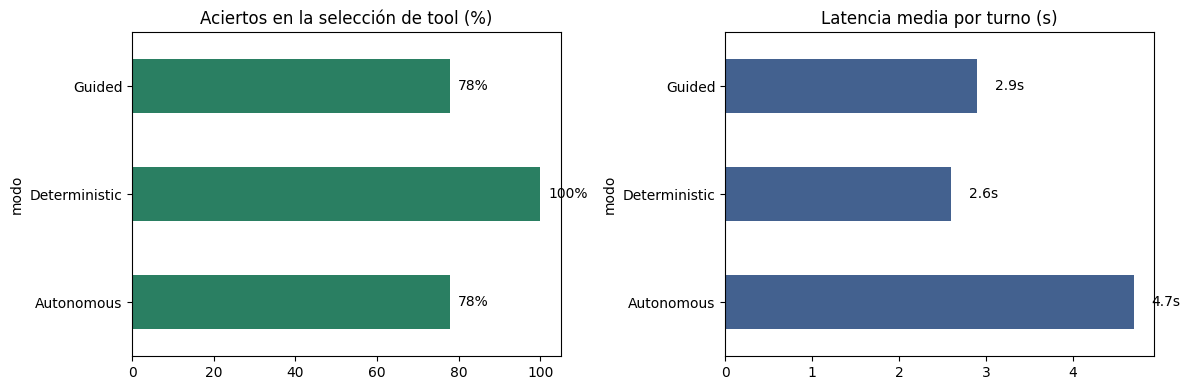

In [54]:
# Grafico del experimento: acierto (%) y latencia media (s) por modo.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
resumen['acierto_pct'].plot.barh(ax=ax[0], color='#2a7f62')
ax[0].set_xlim(0, 105)
ax[0].set_title('Aciertos en la selección de tool (%)')
for i, v in enumerate(resumen['acierto_pct']):
    ax[0].text(v + 2, i, f'{v:.0f}%', va='center')

resumen['latencia_media_s'].plot.barh(ax=ax[1], color='#43618f')
ax[1].set_title('Latencia media por turno (s)')
for i, v in enumerate(resumen['latencia_media_s']):
    ax[1].text(v + 0.2, i, f'{v:.1f}s', va='center')
plt.tight_layout()
plt.show()


**Observación (corrida real, lectura del experimento).** El cuadro y la figura permiten la comparación directa: Deterministic lidera en acierto (100%) y en latencia media (2.6 s, p90 6.2 s); Guided acierta 77.8% con 2.9 s de media (p90 8.7 s, marcado por los dos turnos de `general` con 8.6 y 9.3 s) y Autonomous empareja el acierto de Guided (77.8%) al coste de ser el modo más lento (4.7 s), porque cada decisión encadena turnos adicionales del LLM. La hipótesis previa de que Guided sería el mejor equilibrio quedó corregida por la corrida: con un LLM de 3 B, darle la decisión no añade acierto (77.8% en ambos modos) y solo añade latencia o llamadas donde no corresponde. Recomendación para la demo del video: Deterministic como modo principal, que es donde el protocolo muestra su propuesta de valor (el host ejecuta la herramienta y el LLM solo redacta), reservando Guided para consultas libres fuera de la heurística.

## 10. De la consola a la interfaz: el chatbot con Gradio

El mismo agente, montado en una interfaz de chat con Gradio, en la línea del notebook guía. El único control funcional es el selector de herramienta: todo lo demás se infiere del mensaje. La traza MCP puede mostrarse debajo de cada respuesta para que la demo evidencie qué servidor respondió.

In [55]:
# Interfaz Gradio del asistente culinario con herramientas MCP. La funcion es
# async porque Gradio la ejecuta en su propio bucle de eventos y `responder`
# es asincrona (llama al agente con await).
import gradio as gr

async def chat_turno(mensaje, historial, modo, preferida, mostrar_trace):
    respuesta, traza, seg = await responder(mensaje, modo=modo, preferida=preferida,
                                            historial=historial)
    if mostrar_trace:
        respuesta = (respuesta + '\n\n---\nTraza MCP: modo=' + traza['modo']
                     + ' | tools=' + ','.join(traza['tools_usadas'] or ['-'])
                     + ' | ' + f'{seg:.1f} s')
    historial = historial + [
        {'role': 'user', 'content': mensaje},
        {'role': 'assistant', 'content': respuesta},
    ]
    return '', historial

def limpiar():
    return '', []

print('Interfaz lista.')


Interfaz lista.


In [56]:
with gr.Blocks() as gr_blocks:
    gr.Markdown('## Asistente culinario MCP — recetas con fuentes y cálculo exacto')
    gr.Markdown('Pregunte por recetas (responde con la URL de la fuente) o pida cálculos de cocina (conversiones, escalado, kcal).')

    modo = gr.Dropdown(choices=['Guided', 'Autonomous', 'Deterministic'], value='Guided',
                       label='Modo de ejecución')
    preferida = gr.Dropdown(choices=['Auto', 'buscar_recetas', 'convertir_volumen', 'escalar_cantidad', 'calcular_kcal'],
                            value='Auto', label='Tool preferida')
    traza_chk = gr.Checkbox(label='Mostrar traza MCP bajo la respuesta', value=False)

    chatbot = gr.Chatbot(label='Historial', height=420)
    msg = gr.Textbox(placeholder='Ejemplo: ¿Cómo preparo arepas de queso? / ¿Cuántos ml son 3 tazas?',
                     label='¿Qué quieres preguntar?')
    clear = gr.Button('Limpiar')

    msg.submit(chat_turno, [msg, chatbot, modo, preferida, traza_chk], [msg, chatbot])
    clear.click(limpiar, None, [msg, chatbot], queue=False)

gr_blocks.launch(inline=False)


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7fe1738eff6e1c0f4d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [57]:
gr_blocks.close()


Closing server running on port: 7860


## 11. Apagado limpio

Se cierran los procesos MCP que el notebook mismo inició (los servidores que ya venían de afuera permanecen), para no dejar sesiones colgadas.

In [58]:
# Apagado de los servidores iniciados por este notebook.
for puerto, proc in mcp_procs.items():
    try:
        proc.terminate()
        print(f'Servidor del puerto {puerto} apagado (pid {proc.pid}).')
    except Exception as exc:
        print(f'No se pudo apagar el servidor del puerto {puerto}: {exc}')


Servidor del puerto 9090 apagado (pid 3637).
Servidor del puerto 9091 apagado (pid 3639).


## 12. Conclusiones

1. **El caso resuelto.** Un asistente culinario conversacional sirve 19.249 recetas curadas del mismo corpus del Taller 5 a través de dos servidores MCP propios (FastMCP con transporte streamable-http en los puertos 9090/9091; cinco herramientas descubiertas automáticamente: `buscar_recetas`, `leer_receta`, `convertir_volumen`, `escalar_cantidad`, `calcular_kcal`), con cita por URL de origen y el cálculo (conversiones, escalado, kcal) en un servidor determinístico aparte. La corrida en Colab fue de punta a punta: corpus, Ollama, servidores, agente, experimento de 27 turnos, interfaz Gradio con URL pública y apagado limpio de procesos.

2. **MCP frente al RAG monolítico del Taller 5.** Mismo corpus (19.249 recetas tras una curación idéntica) y mismo generador (`llama3.2:3b`, temperature=0), arquitectura distinta: en el Taller 5 la única herramienta era un vector store embebido en el proceso del chatbot; aquí no hay índice de embeddings, cada capacidad es un servidor independiente cuyo contrato declara `@mcp.tool()` y su docstring, y el agente solo conoce herramientas, nunca el corpus. A cambio, el retriever del Taller 5 sigue dando lo que este servidor no ofrece: búsqueda semántica (hit@1 0.60 y MRR 0.625 con la configuración ganadora A3, frente a la coincidencia léxica del índice invertido), mientras que MCP aporta lo que el RAG no puede dar: herramientas sin semántica como la aritmética (conversiones, kcal, escalado) y una extensibilidad donde agregar el segundo servidor no tocó una línea del agente.

3. **Hallazgos del experimento (9 consultas x 3 modos).** En las categorías con tool esperada (`documentos`, `calculo`) la selección fue perfecta en los tres modos; los cuatro fallos son todos de `general`, donde Guided y Autonomous llamaron a `buscar_recetas` ante saludos y despedidas. El cuadro resultante: **Deterministic 100% de acierto con 2.6 s de media (p90 6.2 s)**, Guided 77.8% con 2.9 s (p90 8.7 s) y Autonomous 77.8% con 4.7 s (p90 7.4 s). La corrida corrigió la hipótesis previa: con un LLM de 3 B, dejarle la decisión no mejora el acierto y solo añade latencia; el modo recomendado para la demo del video es **Deterministic**, con Guided como respaldo para consultas libres fuera de la heurística.

4. **Límites observados en la corrida.** Tres fallas concentradas en la capa de redacción (no en la del protocolo): la primera demostración llamó `leer_receta` sin id, la tool falló y el modelo respondió con una receta de su memoria y "Fuentes:" vacía (88.4 s, primer turno con carga fría de Ollama); la segunda ejecutó el encadenamiento inter-servidores (`buscar_recetas` + `calcular_kcal`) pero la cifra de kcal y la URL se perdieron en la redacción final; y la tercera devolvió 473.2 ml donde la tabla del servidor fija 480 ml, porque el LLM redactor prefirió su propia aritmética al resultado de la herramienta. El mensaje es claro: el protocolo transmite bien los datos, pero la citación y la fidelidad al resultado requieren control mecánico y no confianza en el prompt.

5. **Trabajo futuro.** Acotado por lo observado: (a) sustituir la promesa del prompt por mecanismo, escribiendo la línea "Fuentes:" desde la traza MCP y devolviendo verbatim el resultado de las tools de cálculo; (b) exponer el corpus como recurso MCP y no solo como tool de búsqueda; (c) pruebas de flujo en transporte stdio para uso local y streaming de respuestas largas; y (d) ampliar el experimento con más consultas por categoría (las diferencias actuales se miden sobre 27 turnos) y guardar el índice invertido entre corridas.

## Referencias

- [Model Context Protocol — Specification 2026-07-28](https://modelcontextprotocol.io/specification/2026-07-28)
- [MCP Architecture overview](https://modelcontextprotocol.io/docs/2026-07-28/learn/architecture)
- [MCP Python SDK (FastMCP)](https://py.sdk.modelcontextprotocol.io/)
- [langchain-mcp-adapters](https://pypi.org/project/langchain-mcp-adapters/)
- Dataset: [somosnlp/RecetasDeLaAbuela](https://huggingface.co/datasets/somosnlp/RecetasDeLaAbuela) (Hackathon #Somos600M)
- [Ollama](https://ollama.com/) · [Gradio](https://www.gradio.app/) · [LangChain](https://www.langchain.com/)